# 80. 알고리즘: 우선 지원 순위 백테스트, 이벤트 × 지역 × 업종 시나리오 격자, 기상 이벤트 발생 확률 모델

회의 요청(2026-10-11): "기상 이벤트 × 지역 × 업종 축의 개별 시나리오", "기상 이벤트 발생 예측 모델 및 매출 손실 예측 모델", "알고리즘 빌드".

1. 우선 지원 순위 알고리즘(`priority.py`) 백테스트: 2025년 실제 이벤트일마다, 그 달을 뺀 자료로 학습한 모델이 "전날 정보"로 만든 순위가 실제 손실 순위를 얼마나 맞혔나. 기준선(규모순·민감도순·확률순·무작위)과 비교. 날 단위와 시리즈 누적(한 시즌 동안 누가 가장 많이 잃었나) 두 수준에서 본다. 호우 손실은 시간대별 β(비가 온 시간대의 그 시간대 매출)로 계산하고, 일 단위 β 방식도 비교한다.
2. 시나리오 격자: 호우 3단계 × 더위 3단계 × 요일 2종 × 지역 2 → 소상공인 업종별 예상 손실·경보 확률 표.
3. 기상 이벤트 발생 확률 모델: 1991~2025 장기 자료로 날짜(계절)와 연도 추세에 따른 폭염·열대야·호우 발생 확률을 로지스틱으로 학습(1991~2020), 2021~2025로 검증(Brier 점수). 2026년 날짜별 확률 × 이벤트 하루당 손실 = 기대 손실 캘린더.

입력: `models.py`, `priority.py`, 70번의 `t_best_params.json`(없으면 기본값), 30·50번 표. 출력: `outputs/tables/a_*.csv`, 그림 `a*.png`

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

sys.path.insert(0, str(Path.cwd()))
from common import FIG, TAB, REGIONS, REGION_NAME, FACE_GROUPS, load
from analysis import RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, EVENT_COLOR, exclusion_days, finish
import models as M
import priority as P

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120)
cal = load("calendar"); EXCL = exclusion_days(cal)
panel = load("model_panel_day")
tb_panel = load("model_panel_tb")
best_path = TAB / "t_best_params.json"
best = json.load(open(best_path, encoding="utf-8")) if best_path.exists() else {}
CLS_PARAMS = {**M.CLS_PARAMS, **best.get("cls", {}), "subsample_freq": 1, "random_state": 42, "verbose": -1}
CLS_FEATS = M.CLS_FEAT_EXP if best.get("cls_feat") == "exp" else M.CLS_FEAT
print("분류 파라미터:", {k: CLS_PARAMS[k] for k in ["num_leaves", "learning_rate", "n_estimators", "min_child_samples"]}, "| 피처:", best.get("cls_feat", "base"))
d = M.load_daily()
ev = M.load_events(d)
ev["month"] = ev.date.dt.month
print(f"이벤트일 관측 {len(ev):,}건, 소상공인 {int((ev.small_biz == 1).sum()):,}건")

분류 파라미터: {'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 400, 'min_child_samples': 30} | 피처: base


이벤트일 관측 5,468건, 소상공인 4,434건


C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:37: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = np.log1p(df.pivot_table(index="date", columns=keys, values=value, aggfunc="sum")).reindex(DATES)


## 1. 우선 지원 순위 백테스트

한 달씩 빼고(분류기, 민감도 β, 요일 평상 매출 모두 그 달을 뺀 자료로) 학습한 뒤, 뺀 달의 이벤트일마다 소상공인 업종의 우선순위를 만들고 실제 손실과 비교한다.
- 실제 손실(순효과) = 요일 평상 매출 × (1 − exp(dev)), dev는 같은 요일 앞뒤 2주 기준선 대비 편차. 0에서 자르지 않는다: 자르면 평상시 변동(잡음)이 손실로 잡혀 규모가 큰 업종에 유리해진다. 순위 상관은 순효과로, "상위 10이 포함한 손실 비율"은 실제로 기준선 아래로 떨어진 금액(0에서 자른 값) 기준으로 본다.
- 대상은 호우일(영업시간 10mm 이상)이다. 폭염·열대야일은 평균 손실이 없어서(순효과 ≈ 0 또는 양수) 순위를 매길 손실 자체가 없다. 폭염·열대야일의 결과는 참고로만 둔다.
- 지표: 날마다 (1) 순위 상관(스피어만), (2) 예측 상위 10과 실제 상위 10의 겹침 수, (3) 예측 상위 10이 그날 실제 손실 총액의 몇 %를 포함하나. 그리고 시리즈별로 이벤트일 손실을 누적해 같은 지표를 본다.
- 방법: 알고리즘(예상 손실 = 시간대 β × 요일·시간대 평상 매출, 기본), p × 예상 손실, 사후 기대 β 손실, 일 β 손실, 확률 보정 손실(요일 평상 매출 × (1 − exp(−E[−dev | p]))), 규모순(요일 평상 매출), 확률순(경보 확률만), 무작위(기댓값).

In [2]:
DEV_LO, DEV_HI = np.nanquantile(ev.dev.values, [0.02, 0.98])  # 극단값(기준선이 거의 0인 날 등) 윈저화 경계
print(f"dev 윈저화 경계: {DEV_LO:.2f} ~ {DEV_HI:.2f} (로그)")
rows, sb_all = [], []
for m_ in sorted(ev.month.unique()):
    tr_ev, te_ev = ev[ev.month != m_], ev[ev.month == m_]
    tr_panel = panel[panel.date.dt.month != m_]
    model = P.PriorityModel.fit(tr_ev, tr_panel, tb_panel[tb_panel.date.dt.month != m_], EXCL, CLS_PARAMS, CLS_FEATS)
    sc = model.score(te_ev)
    # 점수(그날 날씨)와 실제 편차를 시리즈·날짜로 맞춘다(업종으로만 맞추면 같은 달의 다른 이벤트일 점수가 섞인다)
    sc = sc.merge(te_ev[["region", "industry", "date", "dev"]].assign(region=lambda x: x.region.astype(str), industry=lambda x: x.industry.astype(str)), on=["region", "industry", "date"])
    assert not sc.duplicated(["region", "industry", "date"]).any()
    sc["dev_w"] = sc.dev.clip(DEV_LO, DEV_HI)
    sc["realized_net"] = sc.base_sales * (1 - np.exp(sc.dev_w))
    sc["realized"] = sc.realized_net.clip(lower=0)
    sb = sc[sc.small_biz == 1]
    sb_all.append(sb)
    sb = sb[sb.w_rain_biz10 == 1]  # 호우일만 순위 평가
    for day, g in sb.groupby("date"):
        tot_loss = g.realized.sum()  # 기준선 아래로 떨어진 금액의 합(0에서 자른 값)
        if len(g) < 15 or tot_loss <= 0:
            continue
        truth = g.realized_net.values  # 순위 상관은 순효과로
        top_true = set(g.nlargest(10, "realized").index)
        rec = {"date": day, "region": g.region.iloc[0] if g.region.nunique() == 1 else "both", "n": len(g), "실제 손실 합(백만)": tot_loss / 1e6}
        for name, col in [("알고리즘(예상 손실)", "priority"), ("p × 예상 손실", "priority_p"), ("사후 기대 β", "priority_post"), ("일 β", "priority_day"),
                          ("확률 보정 손실", "priority_cal"), ("규모순", "base_sales"), ("확률순", "p_alert")]:
            s = g[col].fillna(0)
            top = set(g.nlargest(10, col).index)
            rec[f"{name} 상관"] = spearmanr(s, truth).correlation
            rec[f"{name} 상위10 겹침"] = len(top & top_true)
            rec[f"{name} 상위10 손실 포함(%)"] = g.loc[list(top), "realized"].sum() / tot_loss * 100
        rec["무작위 상위10 손실 포함(%)"] = 10 / len(g) * 100
        rows.append(rec)
bt = pd.DataFrame(rows)
bt.round(3).to_csv(TAB / "a_priority_backtest_daily.csv", index=False, encoding="utf-8-sig")
METH = ["알고리즘(예상 손실)", "p × 예상 손실", "사후 기대 β", "일 β", "확률 보정 손실", "규모순", "확률순"]
summ = pd.DataFrame({m: {"평균 순위 상관": bt[f"{m} 상관"].mean(), "상위10 겹침(평균)": bt[f"{m} 상위10 겹침"].mean(), "상위10 손실 포함(%)": bt[f"{m} 상위10 손실 포함(%)"].mean()} for m in METH}).T
summ.loc["무작위"] = [0.0, 10 * 10 / bt.n.mean(), bt["무작위 상위10 손실 포함(%)"].mean()]
summ.round(3).to_csv(TAB / "a_priority_backtest.csv", encoding="utf-8-sig")
print(f"백테스트 이벤트일 {len(bt)}일(지역별 {bt.region.value_counts().to_dict()})")
# 시리즈 누적: 호우일 손실을 시리즈별로 더해 "한 시즌 동안 누가 많이 잃었나"
SB_ALL = pd.concat(sb_all)
SB = SB_ALL[SB_ALL.w_rain_biz10 == 1].copy()
ref = SB_ALL[SB_ALL.w_rain_biz10 == 0].groupby("region").apply(lambda g: pd.Series({"폭염·열대야일 순 감소율 평균(%)": (1 - np.exp(g.dev_w)).mean() * 100, "예측 손실 평균(백만)": g.expected_loss.mean() / 1e6}), include_groups=False)
print("참고: 호우가 없는 폭염·열대야일"); print(ref.round(2))
cum = SB.groupby(["region", "industry"]).agg(realized_net=("realized_net", "sum"), realized=("realized", "sum"), priority=("priority", "sum"), priority_p=("priority_p", "sum"), priority_day=("priority_day", "sum"), priority_post=("priority_post", "sum"),
                                              priority_cal=("priority_cal", "sum"), base=("base_sales", "sum"), p=("p_alert", "mean"), n_days=("date", "nunique")).reset_index()
cum_rows = {}
for r, g in cum.groupby("region"):
    top_true = set(g.nlargest(10, "realized_net").index)
    for name, col in [("알고리즘(예상 손실)", "priority"), ("p × 예상 손실", "priority_p"), ("사후 기대 β", "priority_post"), ("일 β", "priority_day"),
                      ("확률 보정 손실", "priority_cal"), ("규모순", "base"), ("확률순", "p")]:
        top = set(g.nlargest(10, col).index)
        cum_rows[(REGION_NAME[r], name)] = {"순위 상관": spearmanr(g[col], g.realized_net).correlation, "상위10 겹침": len(top & top_true),
                                             "상위10 손실 포함(%)": g.loc[list(top), "realized"].sum() / g.realized.sum() * 100, "시리즈 수": len(g)}
cum_tab = pd.DataFrame(cum_rows).T
cum_tab.round(3).to_csv(TAB / "a_priority_backtest_cumulative.csv", encoding="utf-8-sig")
print("시리즈 누적 백테스트(소상공인, 2025년 이벤트일 전체):"); print(cum_tab.round(3))
# 손실률 기준(규모를 뺀 순수 예측력): 예측 손실률 = 예상 손실 / 평상 매출, 실제 손실률 = 1 − exp(dev)
SB["pred_rate"] = SB.expected_loss / SB.base_sales
SB["pred_rate_day"] = SB.expected_loss_day / SB.base_sales
SB["pred_rate_post"] = SB.expected_loss_post / SB.base_sales
SB["real_rate"] = 1 - np.exp(SB.dev_w)  # 순 감소율(음수 허용, 윈저화)
rate_rows = []
for day, g in SB.groupby("date"):
    if len(g) < 15 or g.real_rate.sum() <= 0:
        continue
    rate_rows.append({"date": day, "시간대 β 손실률": spearmanr(g.pred_rate, g.real_rate).correlation, "일 β 손실률": spearmanr(g.pred_rate_day, g.real_rate).correlation,
                      "사후 β 손실률": spearmanr(g.pred_rate_post, g.real_rate).correlation, "확률 보정 손실률": spearmanr(g.rate_cal, g.real_rate).correlation,
                      "경보 확률": spearmanr(g.p_alert, g.real_rate).correlation, "p×손실률": spearmanr(g.p_alert * g.pred_rate, g.real_rate).correlation})
rate_day = pd.DataFrame(rate_rows)
cum_rate = SB.groupby(["region", "industry"]).agg(pred_rate=("pred_rate", "mean"), pred_rate_day=("pred_rate_day", "mean"), pred_rate_post=("pred_rate_post", "mean"),
                                                   rate_cal=("rate_cal", "mean"), p=("p_alert", "mean"), real_rate=("real_rate", "mean")).reset_index()
rate_tab = pd.DataFrame({"날 단위(평균 상관)": rate_day.drop(columns="date").mean(),
                         "시리즈 누적(상관)": {"시간대 β 손실률": spearmanr(cum_rate.pred_rate, cum_rate.real_rate).correlation, "일 β 손실률": spearmanr(cum_rate.pred_rate_day, cum_rate.real_rate).correlation,
                                      "사후 β 손실률": spearmanr(cum_rate.pred_rate_post, cum_rate.real_rate).correlation, "확률 보정 손실률": spearmanr(cum_rate.rate_cal, cum_rate.real_rate).correlation,
                                      "경보 확률": spearmanr(cum_rate.p, cum_rate.real_rate).correlation, "p×손실률": spearmanr(cum_rate.p * cum_rate.pred_rate, cum_rate.real_rate).correlation}})
rate_tab.round(3).to_csv(TAB / "a_priority_backtest_rate.csv", encoding="utf-8-sig")
print("손실률 기준 백테스트(규모 제외):"); print(rate_tab.round(3))
summ.round(3)

dev 윈저화 경계: -1.21 ~ 1.30 (로그)


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


백테스트 이벤트일 21일(지역별 {'both': 11, 'chuncheon': 7, 'gangnam': 3})
참고: 호우가 없는 폭염·열대야일
           폭염·열대야일 순 감소율 평균(%)  예측 손실 평균(백만)
region                                      
chuncheon               -14.02          0.48
gangnam                 -10.81         12.68
시리즈 누적 백테스트(소상공인, 2025년 이벤트일 전체):
                순위 상관  상위10 겹침  상위10 손실 포함(%)  시리즈 수
춘천 알고리즘(예상 손실)  0.896      9.0         69.839   40.0
   p × 예상 손실    0.900      8.0         64.320   40.0
   사후 기대 β      0.866      9.0         69.839   40.0
   일 β          0.864      8.0         68.602   40.0
   확률 보정 손실     0.850     10.0         71.006   40.0
   규모순          0.761      8.0         67.518   40.0
   확률순          0.278      3.0         18.479   40.0
강남 알고리즘(예상 손실)  0.459      7.0         55.932   42.0
   p × 예상 손실    0.441      6.0         63.930   42.0
   사후 기대 β      0.445      7.0         55.932   42.0
   일 β          0.412      7.0         55.932   42.0
   확률 보정 손실     0.380      6.0         62.795   42.0
   규모순          

,평균 순위 상관,상위10 겹침(평균),상위10 손실 포함(%)
알고리즘(예상 손실),0.391,5.476,51.574
p × 예상 손실,0.381,5.190,49.854
사후 기대 β,0.388,5.429,51.209
일 β,0.379,5.381,50.172
확률 보정 손실,0.360,4.952,49.964
규모순,0.377,5.238,51.017
확률순,0.031,1.857,19.076
무작위,0.000,1.606,18.123


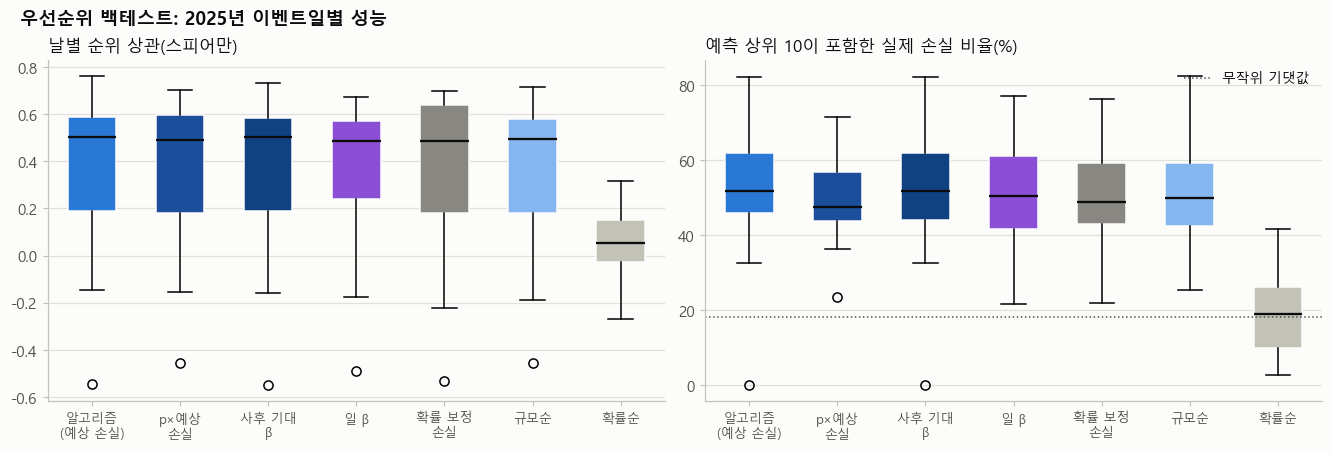

순위 상관  상위10 손실 포함(%)
region    방법                               
both      알고리즘(예상 손실)  0.421         50.577
          p × 예상 손실    0.412         47.881
          사후 기대 β      0.425         50.088
          일 β          0.407         49.550
          확률 보정 손실     0.386         47.134
          규모순          0.409         48.915
          확률순          0.047         14.780
chuncheon 알고리즘(예상 손실)  0.462         62.320
          p × 예상 손실    0.430         54.707
          사후 기대 β      0.444         61.995
          일 β          0.431         57.557
          확률 보정 손실     0.400         58.402
          규모순          0.417         60.593
          확률순         -0.015         23.384
gangnam   알고리즘(예상 손실)  0.115         30.154
          p × 예상 손실    0.153         45.763
          사후 기대 β      0.118         30.154
          일 β          0.160         35.218
          확률 보정 손실     0.169         40.651
          규모순          0.171         36.382
          확률순          0.083         24.775

In [3]:
by_region = pd.concat({r: pd.DataFrame({m: {"순위 상관": g[f"{m} 상관"].mean(), "상위10 손실 포함(%)": g[f"{m} 상위10 손실 포함(%)"].mean()} for m in METH}).T for r, g in bt.groupby("region")}, names=["region", "방법"])
by_region.round(3).to_csv(TAB / "a_priority_backtest_region.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, (col, ttl) in zip(axes, [("상관", "날별 순위 상관(스피어만)"), ("상위10 손실 포함(%)", "예측 상위 10이 포함한 실제 손실 비율(%)")]):
    data = [bt[f"{m} {col}"].dropna() for m in METH]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color=INK, lw=1.5))
    for patch, c in zip(bp["boxes"], ["#2a78d6", "#1b4f9c", "#104281", "#8b4fd6", "#898781", "#86b6ef", "#c3c2b7"]):
        patch.set_facecolor(c); patch.set_edgecolor(SURFACE)
    ax.set_xticks(range(1, 8), ["알고리즘\n(예상 손실)", "p×예상\n손실", "사후 기대\nβ", "일 β", "확률 보정\n손실", "규모순", "확률순"], fontsize=8.5); ax.set_title(ttl); ax.grid(axis="x", visible=False)
    if col == "상위10 손실 포함(%)":
        ax.axhline(bt["무작위 상위10 손실 포함(%)"].mean(), color=INK2, lw=1, ls=":", label="무작위 기댓값"); ax.legend(loc="upper right")
finish(fig, FIG, "a01_backtest", "우선순위 백테스트: 2025년 이벤트일별 성능")
plt.show()
by_region.round(3)

## 2. 이벤트 × 지역 × 업종 시나리오 격자

전체 자료로 학습한 최종 모델로, 호우 3단계(10·20·40mm, 낮 시간대 중심) × 더위 3단계(없음·폭염 33℃·폭염 36℃+열대야) × 요일 2종(수·토) × 지역 2곳의 36개 시나리오에서 소상공인 업종별 경보 확률·예상 손실을 만든다. 예상 손실은 시간대 β 방식(기본)과 확률 보정 방식을 같이 둔다.

In [4]:
final = P.PriorityModel.fit(ev, panel, tb_panel, EXCL, CLS_PARAMS, CLS_FEATS)
RAIN = {"비 없음": dict(rn_06=0, rn_12=0, rn_18=0), "호우 10mm(낮)": dict(rn_06=2, rn_12=6, rn_18=2), "호우 20mm(낮·저녁)": dict(rn_06=3, rn_12=10, rn_18=7), "호우 40mm(종일)": dict(rn_06=10, rn_12=18, rn_18=12)}
HEAT = {"더위 없음": dict(ta_max=28, feels_max=28, night_min=20, hm=60), "폭염 33℃": dict(ta_max=33.5, feels_max=33, night_min=24, hm=60, heat_streak=1),
        "폭염 36℃+열대야": dict(ta_max=36, feels_max=35, night_min=27, hm=60, heat_streak=3)}
DOW = {"수요일": ("2025-08-20", "2025-09-24"), "토요일": ("2025-08-23", "2025-09-27")}
rows = []
for region in REGIONS:
    face_rows = d[(d.region.astype(str) == region) & (d.face == 1)]
    for dname, (hot_date, cool_date) in DOW.items():
        for hname, hw in HEAT.items():
            for rname, rw in RAIN.items():
                if rname == "비 없음" and hname == "더위 없음":
                    continue
                tmpl_date = pd.Timestamp(hot_date if hname != "더위 없음" else cool_date)
                tmpl = face_rows[face_rows.date == tmpl_date]
                wx = P.scenario_weather(**{**rw, **hw}) if hname != "더위 없음" else P.scenario_weather(**rw, hm=85 if rname != "비 없음" else 60)
                sc = final.scenario(tmpl, wx)
                sb = sc[sc.small_biz == 1]
                top = sb.head(5)
                rows.append({"region": region, "요일": dname, "더위": hname, "호우": rname, "소상공인 예상 손실(억)": sb.expected_loss.sum() / 1e8, "확률 보정 손실(억)": sb.expected_loss_cal.sum() / 1e8,
                             "경보 확률 평균": sb.p_alert.mean(), "경보(p≥0.5) 업종 수": int((sb.p_alert >= 0.5).sum()), "상위 5 업종": ", ".join(top.industry),
                             "대면 전체 예상 손실(억)": sc.expected_loss.sum() / 1e8})
grid = pd.DataFrame(rows)
grid.round(3).to_csv(TAB / "a_scenario_grid.csv", index=False, encoding="utf-8-sig")
piv = grid.pivot_table(index=["region", "요일", "더위"], columns="호우", values="소상공인 예상 손실(억)").reindex(columns=list(RAIN))
piv.round(2)

C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


C:\Users\nk233\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1884: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


호우                        비 없음  호우 10mm(낮)  호우 20mm(낮·저녁)  호우 40mm(종일)
region    요일  더위                                                      
chuncheon 수요일 더위 없음        NaN        3.25           3.70         4.21
              폭염 33℃      0.00        3.25           3.70         4.21
              폭염 36℃+열대야  0.00        3.25           3.70         4.21
          토요일 더위 없음        NaN        4.80           5.49         6.13
              폭염 33℃      0.00        4.80           5.49         6.13
              폭염 36℃+열대야  0.00        4.80           5.49         6.13
gangnam   수요일 더위 없음        NaN       13.70          18.19        20.59
              폭염 33℃      0.00       13.70          18.19        20.59
              폭염 36℃+열대야  0.03       13.74          18.23        20.62
          토요일 더위 없음        NaN       16.63          22.10        24.13
              폭염 33℃      0.00       16.63          22.10        24.13
              폭염 36℃+열대야  0.05       16.68          22.15        24.18

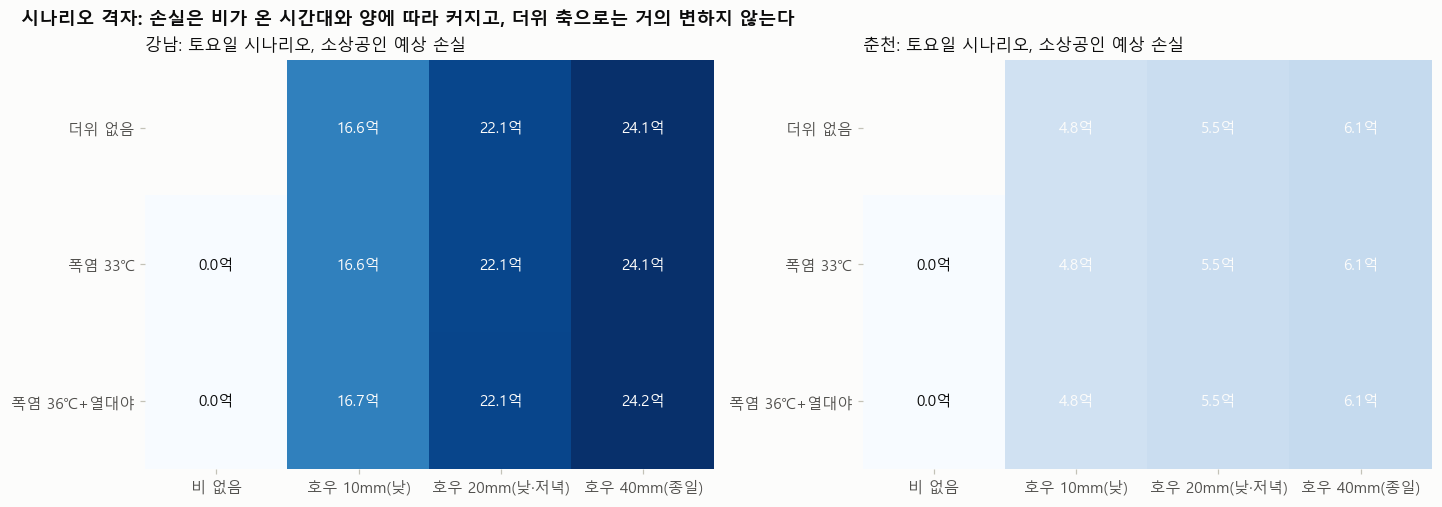

,region,더위,호우,소상공인 예상 손실(억),경보(p≥0.5) 업종 수,상위 5 업종
11,gangnam,더위 없음,호우 10mm(낮),16.63,14,"의복/의류, 한식, 커피전문점, 기타요식, 미용실"
12,gangnam,더위 없음,호우 20mm(낮·저녁),22.10,10,"의복/의류, 한식, 기타요식, 커피전문점, 미용실"
13,gangnam,더위 없음,호우 40mm(종일),24.13,13,"의복/의류, 한식, 기타요식, 커피전문점, 미용실"
14,gangnam,폭염 33℃,비 없음,0.00,3,"가구, 애완동물, 완구/아동용자전거, 유흥업소, 의복/의류"
15,gangnam,폭염 33℃,호우 10mm(낮),16.63,2,"의복/의류, 한식, 커피전문점, 기타요식, 미용실"
16,gangnam,폭염 33℃,호우 20mm(낮·저녁),22.10,1,"의복/의류, 한식, 기타요식, 커피전문점, 미용실"
17,gangnam,폭염 33℃,호우 40mm(종일),24.13,3,"의복/의류, 한식, 기타요식, 커피전문점, 미용실"
18,gangnam,폭염 36℃+열대야,비 없음,0.05,5,"화원, 싸우나/목욕탕, 문화용품, 가구, 제과점"
19,gangnam,폭염 36℃+열대야,호우 10mm(낮),16.68,7,"의복/의류, 한식, 커피전문점, 기타요식, 미용실"
20,gangnam,폭염 36℃+열대야,호우 20mm(낮·저녁),22.15,7,"의복/의류, 한식, 기타요식, 커피전문점, 미용실"


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, region in zip(axes, REGIONS):
    m = grid[(grid.region == region) & (grid.요일 == "토요일")].pivot_table(index="더위", columns="호우", values="소상공인 예상 손실(억)").reindex(index=list(HEAT), columns=list(RAIN))
    im = ax.imshow(m.values, cmap=plt.cm.Blues, vmin=0, vmax=np.nanmax(grid["소상공인 예상 손실(억)"]), aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.1f}억", ha="center", va="center", fontsize=10, color=INK if v < np.nanmax(m.values) * 0.6 else SURFACE)
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(m.shape[0]), m.index); ax.set_title(f"{REGION_NAME[region]}: 토요일 시나리오, 소상공인 예상 손실"); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
finish(fig, FIG, "a02_scenario_grid", "시나리오 격자: 손실은 비가 온 시간대와 양에 따라 커지고, 더위 축으로는 거의 변하지 않는다")
plt.show()
grid[grid.요일 == "토요일"][["region", "더위", "호우", "소상공인 예상 손실(억)", "경보(p≥0.5) 업종 수", "상위 5 업종"]].round(2)

## 3. 기상 이벤트 발생 확률 모델(기후학적)

1991~2025 일자료(서울 108·춘천 101)로 이벤트(폭염일, 열대야, 일 10mm+)의 발생 확률을 `logit(p) = 계절 조화항(sin/cos 1~3차) + 연도 추세`로 학습한다.
- 학습 1991~2020, 검증 2021~2025: Brier 점수를 "계절만(추세 없음)" 모델, "평년 빈도" 기준과 비교.
- 2026년 7~12월 날짜별 확률을 내고, 이벤트 하루당 손실(30번, 소상공인)과 곱해 기대 손실 캘린더를 만든다. 호우는 일 10mm+ 확률에 2025년의 영업시간 10mm+ 비율을 곱한다.

In [6]:
long = load("weather_long_daily")
long["t"] = long.year - 2005
def harmonics(doy, k=3):
    X = {}
    for j in range(1, k + 1):
        X[f"s{j}"] = np.sin(2 * np.pi * j * doy / 365.25); X[f"c{j}"] = np.cos(2 * np.pi * j * doy / 365.25)
    return pd.DataFrame(X)
EVL = {"heat_day": ("heat33", "폭염일"), "tropical": ("tropical25", "열대야"), "rain_biz10": ("rain10", "일 10mm+")}
rows, models_fit = [], {}
for region in REGIONS:
    g = long[long.region == region].dropna(subset=["ta_max", "ta_min"]).copy()
    H = harmonics(g.doy.values); X_season = H.values; X_trend = np.column_stack([H.values, g.t.values])
    train, test = (g.year <= 2020).values, (g.year >= 2021).values
    for ev, (col, name) in EVL.items():
        y = g[col].values
        m_tr = LogisticRegression(C=1e6, max_iter=5000).fit(X_trend[train], y[train])
        m_se = LogisticRegression(C=1e6, max_iter=5000).fit(X_season[train], y[train])
        p_tr, p_se = m_tr.predict_proba(X_trend[test])[:, 1], m_se.predict_proba(X_season[test])[:, 1]
        clim = pd.Series(y[train]).groupby(g.doy.values[train]).mean()
        p_cl = pd.Series(g.doy.values[test]).map(clim).fillna(y[train].mean()).values
        models_fit[(region, ev)] = LogisticRegression(C=1e6, max_iter=5000).fit(X_trend, y)  # 2026 예측용은 전체로 다시 학습
        rows.append({"region": region, "이벤트": name, "검증 실제 일수/년": y[test].sum() / 5, "추세 모델 예측 일수/년": p_tr.sum() / 5, "계절만 예측 일수/년": p_se.sum() / 5,
                     "Brier 추세": brier_score_loss(y[test], p_tr), "Brier 계절만": brier_score_loss(y[test], p_se), "Brier 평년빈도": brier_score_loss(y[test], p_cl),
                     "연도 추세 계수(로짓/년)": m_tr.coef_[0][-1]})
evm = pd.DataFrame(rows)
evm.round(4).to_csv(TAB / "a_event_prob_model.csv", index=False, encoding="utf-8-sig")
evm.round(3)

,region,이벤트,검증 실제 일수/년,추세 모델 예측 일수/년,계절만 예측 일수/년,Brier 추세,Brier 계절만,Brier 평년빈도,연도 추세 계수(로짓/년)
0,gangnam,폭염일,21.6,13.712,8.670,0.042,0.046,0.047,0.035
1,gangnam,열대야,29.2,17.621,10.917,0.045,0.053,0.054,0.045
2,gangnam,일 10mm+,36.2,31.446,32.921,0.085,0.085,0.087,-0.003
3,chuncheon,폭염일,22.8,15.564,11.414,0.044,0.047,0.047,0.023
4,chuncheon,열대야,8.4,9.724,3.020,0.018,0.020,0.021,0.094
5,chuncheon,일 10mm+,36.0,33.234,32.156,0.083,0.084,0.084,0.002


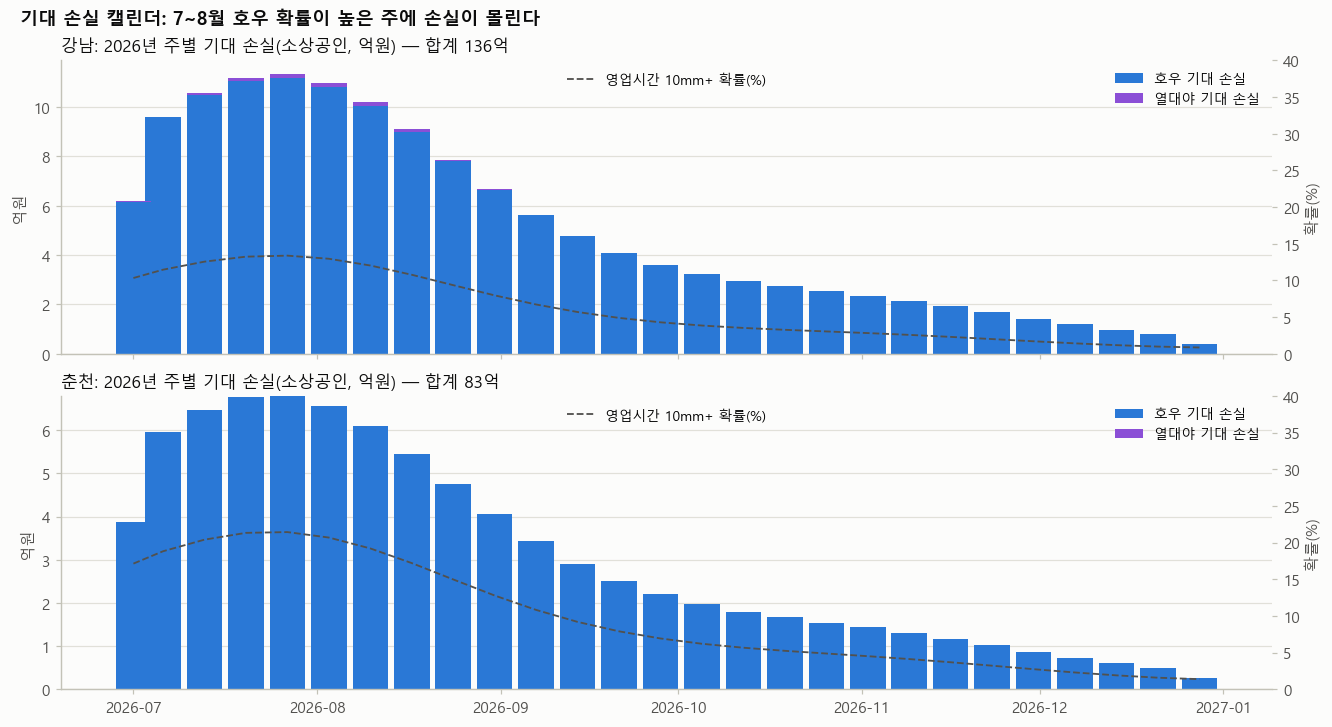

2026년 7~12월 기대 손실(억원, 추세 모델):


,exp_loss_rain_biz10,exp_loss_tropical,exp_loss_heat_day,exp_loss
region,,,,
chuncheon,82.7,0.0,0.6,83.2
gangnam,135.3,0.8,0.0,136.1


In [7]:
# 2026년 7~12월 날짜별 확률 → 기대 손실 캘린더(소상공인)
perday = pd.read_csv(TAB / "v_perday.csv", encoding="utf-8-sig")
w25 = load("weather_daily").query("'2025-07-01' <= date <= '2025-12-31'")
dates = pd.date_range("2026-07-01", "2026-12-31")
rows = []
for region in REGIONS:
    sb = perday[(perday.region == region) & (perday.face == 1) & (perday.small_biz == 1)]
    loss_day = {ev: sb[f"loss_per_day_{ev}"].fillna(0).sum() for ev in EVL}
    long25 = long[(long.region == region) & (long.year == 2025) & (long.month >= 7)]
    ratio = {"heat_day": w25[w25.region == region].heat_day.sum() / max(1, long25.heat33.sum()), "tropical": w25[w25.region == region].tropical.sum() / max(1, long25.tropical25.sum()),
             "rain_biz10": w25[w25.region == region].rain_biz10.sum() / max(1, long25.rain10.sum())}
    H = harmonics(dates.dayofyear.values); X = np.column_stack([H.values, np.full(len(dates), 2026 - 2005)])
    f = pd.DataFrame({"region": region, "date": dates})
    for ev in EVL:
        f[f"p_{ev}"] = models_fit[(region, ev)].predict_proba(X)[:, 1] * ratio[ev]
        f[f"exp_loss_{ev}"] = f[f"p_{ev}"] * loss_day[ev]
    f["exp_loss"] = f[[f"exp_loss_{ev}" for ev in EVL]].sum(axis=1)
    rows.append(f)
calz = pd.concat(rows, ignore_index=True)
calz["week"] = calz.date.dt.isocalendar().week.astype(int)
calz.round(5).to_csv(TAB / "a_expected_loss_calendar_2026.csv", index=False, encoding="utf-8-sig")
wk = calz.groupby(["region", "week"]).agg(week_start=("date", "min"), p_rain=("p_rain_biz10", "mean"), p_heat=("p_heat_day", "mean"), exp_loss_억=("exp_loss", lambda s: s.sum() / 1e8),
                                          exp_rain_억=("exp_loss_rain_biz10", lambda s: s.sum() / 1e8), exp_tropical_억=("exp_loss_tropical", lambda s: s.sum() / 1e8)).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, layout="constrained")
for ax, r in zip(axes, REGIONS):
    x = wk[wk.region == r]
    ax.bar(x.week_start, x.exp_rain_억, width=6, color="#2a78d6", label="호우 기대 손실")
    ax.bar(x.week_start, x.exp_tropical_억, width=6, bottom=x.exp_rain_억, color="#8b4fd6", label="열대야 기대 손실")
    ax2 = ax.twinx(); ax2.plot(x.week_start, x.p_rain * 100, color=INK2, lw=1.2, ls="--", label="영업시간 10mm+ 확률(%)"); ax2.set_ylim(0, 40); ax2.set_ylabel("확률(%)"); ax2.grid(False)
    ax.set_title(f"{REGION_NAME[r]}: 2026년 주별 기대 손실(소상공인, 억원) — 합계 {x.exp_loss_억.sum():.0f}억"); ax.set_ylabel("억원"); ax.grid(axis="x", visible=False)
    ax.legend(loc="upper right"); ax2.legend(loc="upper center")
finish(fig, FIG, "a03_expected_loss_calendar", "기대 손실 캘린더: 7~8월 호우 확률이 높은 주에 손실이 몰린다")
plt.show()
total = calz.groupby("region")[["exp_loss_rain_biz10", "exp_loss_tropical", "exp_loss_heat_day", "exp_loss"]].sum() / 1e8
print("2026년 7~12월 기대 손실(억원, 추세 모델):"); total.round(1)

## 4. 시즌 단위 지원 대상 목록(2026년 7~12월)

백테스트 결론대로 "어느 업종을 시즌 단위로 지원할지"를 낸다. 시리즈별 기대 손실 = Σ_날짜 (이벤트 확률 × 이벤트 하루당 손실). 업소 수(상가정보)를 붙여 업소당 기대 손실도 본다.

In [8]:
ind = load("stores_industry")
rows = []
for region in REGIONS:
    sb = perday[(perday.region == region) & (perday.face == 1) & (perday.small_biz == 1)].copy()
    f = calz[calz.region == region]
    for ev in EVL:
        sb[f"exp_{ev}"] = sb[f"loss_per_day_{ev}"].fillna(0) * f[f"p_{ev}"].sum()
    sb["exp_loss"] = sb[[f"exp_{ev}" for ev in EVL]].sum(axis=1)
    rows.append(sb)
season = pd.concat(rows).merge(ind, on=["region", "industry"], how="left")
season["exp_loss_억"] = season.exp_loss / 1e8
season["업소당_만원"] = season.exp_loss / season.n_stores / 1e4
season["기대 손실률(%)"] = season.exp_loss / (season.sales_day * 184) * 100
season = season.sort_values(["region", "exp_loss"], ascending=[True, False])
season.round(3).to_csv(TAB / "a_season_support_2026.csv", index=False, encoding="utf-8-sig")
show = season.groupby("region").head(10)[["region", "industry", "group", "grade_V", "exp_loss_억", "기대 손실률(%)", "n_stores", "업소당_만원"]].round(2)
print("2026년 7~12월 기대 손실 합계(소상공인):", season.groupby("region").exp_loss.sum().div(1e8).round(1).to_dict())
show

2026년 7~12월 기대 손실 합계(소상공인): {'chuncheon': 83.2, 'gangnam': 136.1}


,region,industry,group,grade_V,exp_loss_억,기대 손실률(%),n_stores,업소당_만원
78,chuncheon,한식,음식점,보통,27.73,1.22,2777.0,99.85
45,chuncheon,기타요식,음식점,보통,11.16,1.25,1022.0,109.21
77,chuncheon,편의점,식품·생필품,보통,5.08,0.61,373.0,136.26
44,chuncheon,기타식품,식품·생필품,보통,3.25,0.60,282.0,115.16
58,chuncheon,스포츠/레저용품,생활·기타소매,보통,3.19,1.00,104.0,306.93
68,chuncheon,인테리어/건축자재/주방기구,생활·기타소매,매우 취약,2.95,1.92,207.0,142.43
69,chuncheon,일식,음식점,취약,2.77,1.82,134.0,206.69
52,chuncheon,미용실,개인서비스,보통,2.71,1.47,903.0,30.03
74,chuncheon,커피전문점,카페·베이커리,취약,2.50,1.57,827.0,30.29
67,chuncheon,의복/의류,패션·잡화,취약,2.41,1.38,641.0,37.62


## 요약

- `a_priority_backtest.csv`: 우선순위 알고리즘이 실제 손실 순위를 얼마나 맞혔나(기준선 대비).
- `a_scenario_grid.csv`: 이벤트 × 지역 × 요일 시나리오별 소상공인 예상 손실과 상위 업종.
- `a_event_prob_model.csv`: 이벤트 발생 확률 모델 검증. `a_expected_loss_calendar_2026.csv`: 2026년 기대 손실 캘린더.

In [9]:
summary = pd.DataFrame({"백테스트 순위 상관(알고리즘/규모순)": [f"{summ.loc['알고리즘(예상 손실)', '평균 순위 상관']:.2f} / {summ.loc['규모순', '평균 순위 상관']:.2f}"],
                        "상위10 손실 포함(알고리즘/규모순/무작위, %)": [f"{summ.loc['알고리즘(예상 손실)', '상위10 손실 포함(%)']:.0f} / {summ.loc['규모순', '상위10 손실 포함(%)']:.0f} / {summ.loc['무작위', '상위10 손실 포함(%)']:.0f}"],
                        "토요일 호우 40mm 소상공인 손실(강남/춘천, 억)": [f"{grid[(grid.region == 'gangnam') & (grid.요일 == '토요일') & (grid.호우 == '호우 40mm(종일)') & (grid.더위 == '더위 없음')]['소상공인 예상 손실(억)'].iloc[0]:.1f} / {grid[(grid.region == 'chuncheon') & (grid.요일 == '토요일') & (grid.호우 == '호우 40mm(종일)') & (grid.더위 == '더위 없음')]['소상공인 예상 손실(억)'].iloc[0]:.1f}"],
                        "2026 기대 손실(강남/춘천, 억)": [f"{total.loc['gangnam', 'exp_loss']:.0f} / {total.loc['chuncheon', 'exp_loss']:.0f}"]}).T
summary.to_csv(TAB / "a_summary.csv", encoding="utf-8-sig")
summary

,0
백테스트 순위 상관(알고리즘/규모순),0.39 / 0.38
"상위10 손실 포함(알고리즘/규모순/무작위, %)",52 / 51 / 18
"토요일 호우 40mm 소상공인 손실(강남/춘천, 억)",24.1 / 6.1
"2026 기대 손실(강남/춘천, 억)",136 / 83
